# 05 · Agent Performance & Productivity

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.2f}".format)
from src.data_cleaning.loader import load_all_processed, load_all_raw
from src.kpi.kpis import kpi_by, compute_all_kpis
from src.analytics import eda
d = load_all_processed()
t, f, o, c = d["tickets_enriched"], d["customer_feedback"], d["operations"], d["customers"]
VIS = ROOT / "visualizations"
def show(*names):
    for n in names: display(Image(filename=str(VIS / f"{n}.png"), width=820))

In [2]:
sc = eda.agent_scorecard(t, d["agent_performance"], d["agents"])
sc[["agent_name","department_id","experience_level","tickets","resolved","resolution_rate_pct","avg_resolution_h","sla_compliance_pct","fcr_pct","reopen_pct","avg_csat","tickets_per_active_month","productivity_rank"]].head(15)

,agent_name,department_id,experience_level,tickets,resolved,resolution_rate_pct,avg_resolution_h,sla_compliance_pct,fcr_pct,reopen_pct,avg_csat,tickets_per_active_month,productivity_rank
0,Elizabeth Fowler,DEP-03,Mid-Level,895.00,859.00,95.98,22.03,86.35,28.94,5.47,3.87,24.90,1
1,Rebecca Henderson,DEP-02,Senior,828.00,799.00,96.50,28.05,78.10,23.90,6.63,3.96,23.00,2
2,Paula Moreno,DEP-04,Lead,784.00,757.00,96.56,36.61,69.89,15.52,5.55,3.62,21.80,3
3,Justin Baker,DEP-02,Mid-Level,735.00,709.00,96.46,34.68,72.21,21.58,9.17,3.75,20.40,4
4,Stephanie Ross,DEP-02,Mid-Level,732.00,708.00,96.72,38.92,71.57,19.09,10.73,3.77,20.30,5
5,Lisa Hensley,DEP-01,Mid-Level,721.00,705.00,97.78,35.99,69.22,19.01,8.23,3.81,20.00,6
6,Brian Ramirez,DEP-01,Senior,677.00,652.00,96.31,28.11,77.23,21.85,7.82,3.61,18.80,7
7,Anthony Rodriguez,DEP-02,Junior,669.00,648.00,96.86,49.69,62.81,15.28,14.97,3.44,19.10,8
8,Carla Gray,DEP-01,Mid-Level,599.00,577.00,96.33,34.33,68.98,20.62,12.82,3.55,16.60,9
9,Jessica Holmes,DEP-05,Junior,597.00,577.00,96.65,83.11,32.52,6.78,21.14,3.38,16.60,9


In [3]:
display(eda.experience_level_summary(t)); display(eda.workload_vs_resolution(d["agent_performance"]))

,experience_level,tickets,resolved,open,avg_frt_h,avg_resolution_h,median_resolution_h,sla_compliance_pct,fcr_pct,escalation_pct,reopen_pct,avg_csat,csat_rate_pct,surveys
0,Junior,"2,748.00","2,647.00",44.00,5.99,58.83,37.44,53.23,13.69,14.46,16.58,3.41,48.79,"1,486.00"
1,Mid-Level,"9,257.00","8,961.00",95.00,5.79,34.63,22.43,72.01,21.14,10.98,8.75,3.74,63.06,"4,784.00"
2,Senior,"7,707.00","7,471.00",84.00,5.74,29.27,18.60,76.80,23.75,9.49,6.33,3.82,66.31,"3,927.00"
3,Lead,"4,273.00","4,142.00",34.00,5.56,27.80,17.97,80.42,23.11,7.21,5.67,3.88,68.81,"2,113.00"


,assigned_bucket,agent_months,avg_assigned,avg_resolution_h,avg_sla_pct
0,"(-0.001, 6.0]",414,4.50,32.59,74.50
1,"(6.0, 9.0]",424,8.00,32.35,75.29
2,"(9.0, 12.0]",403,11.00,31.97,75.24
3,"(12.0, 17.0]",396,14.70,32.20,75.59
4,"(17.0, 46.0]",347,23.10,37.28,69.56


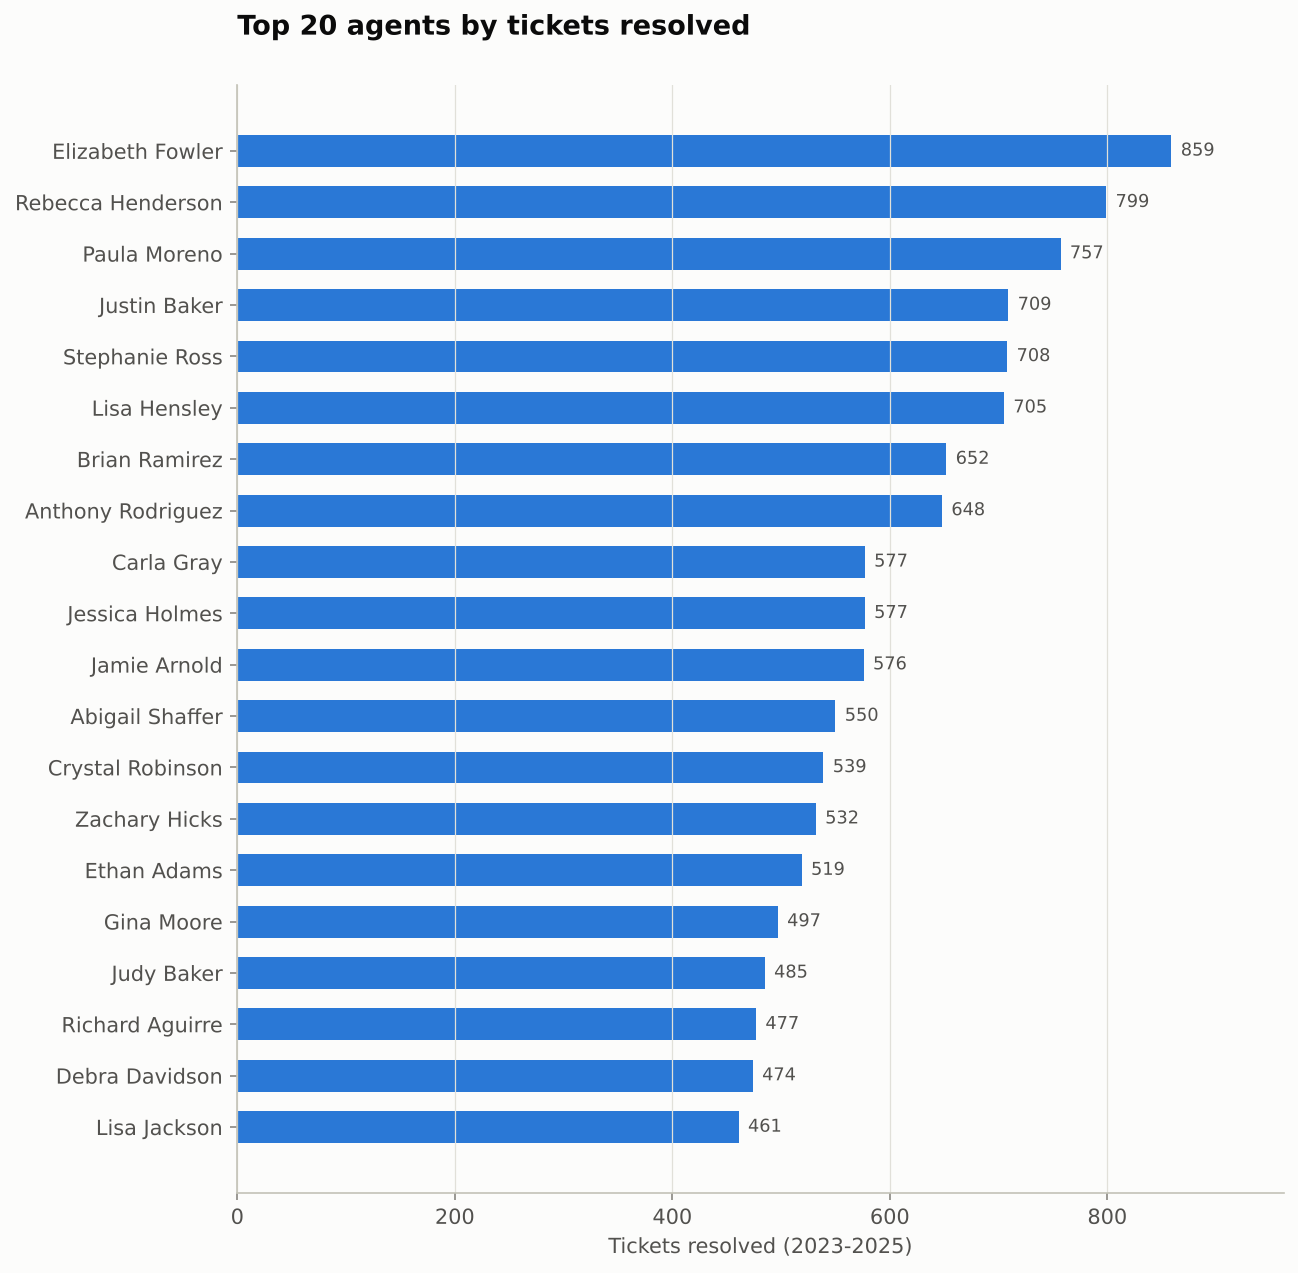

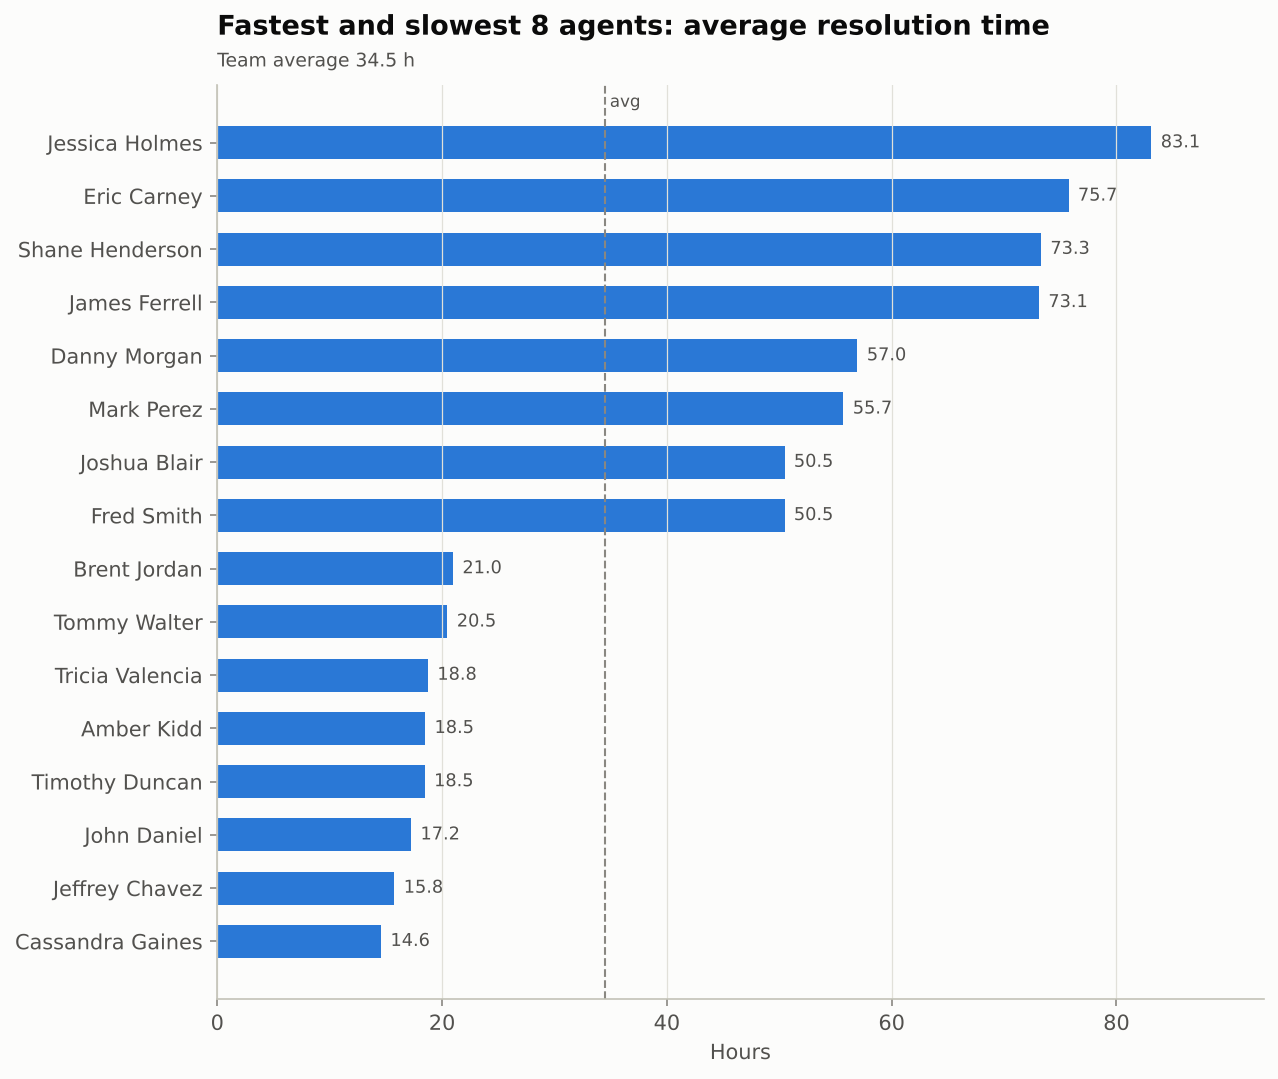

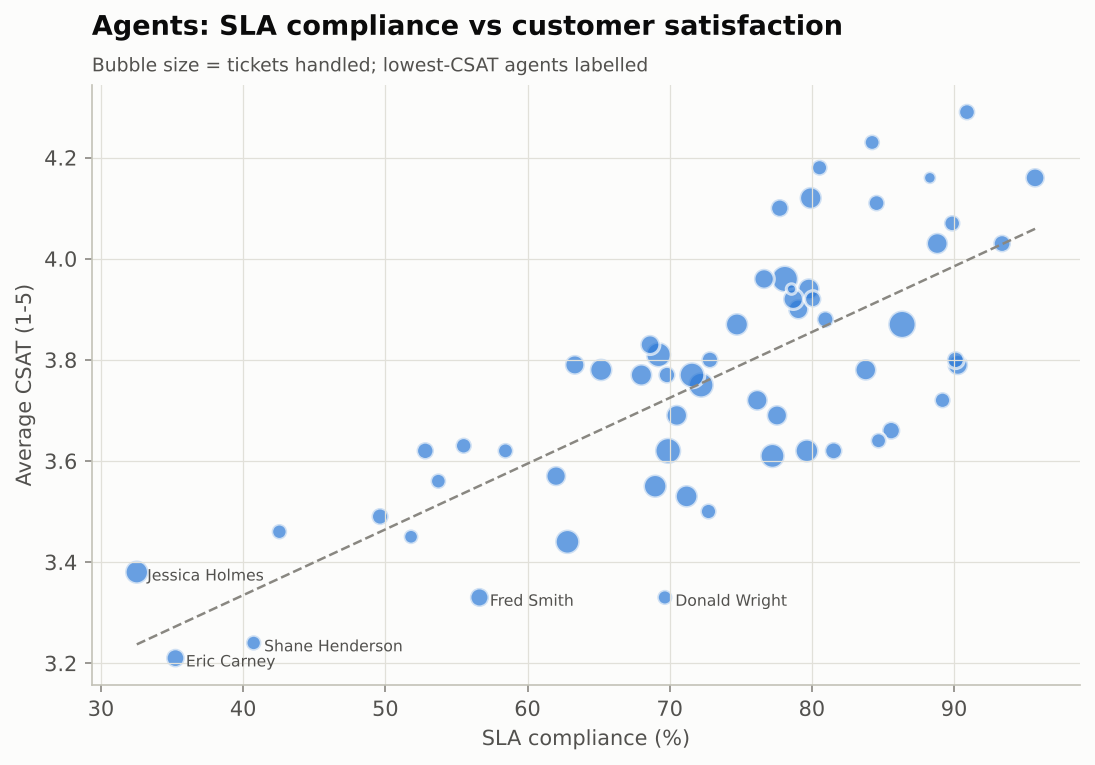

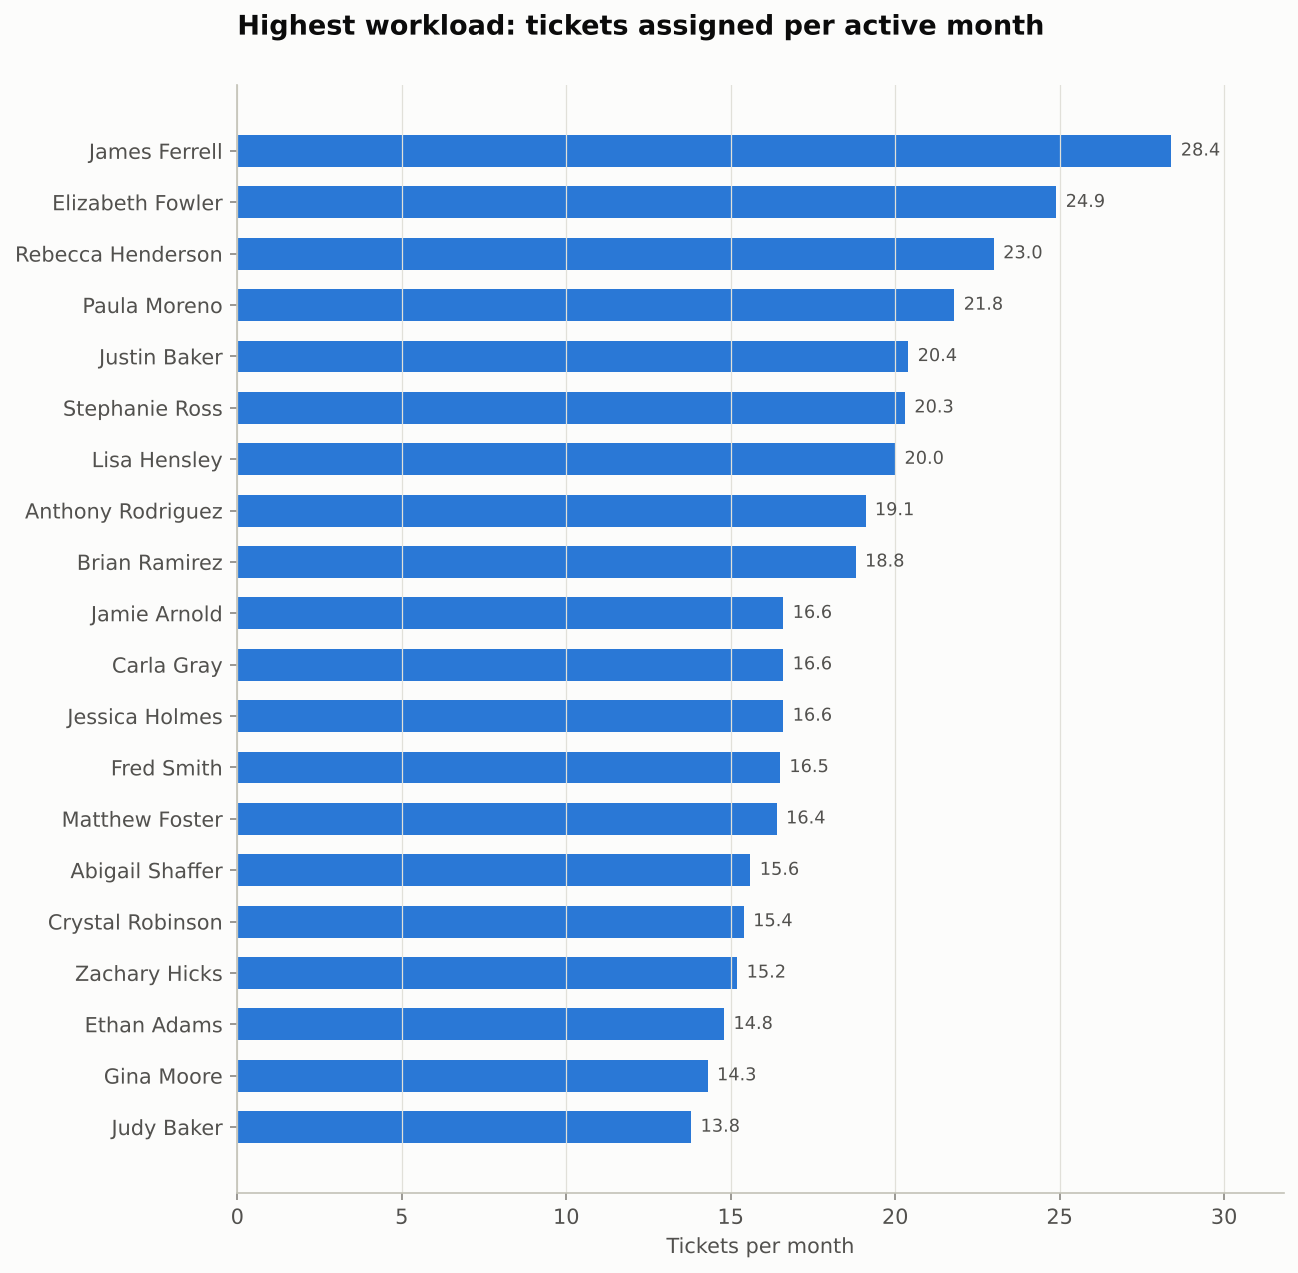

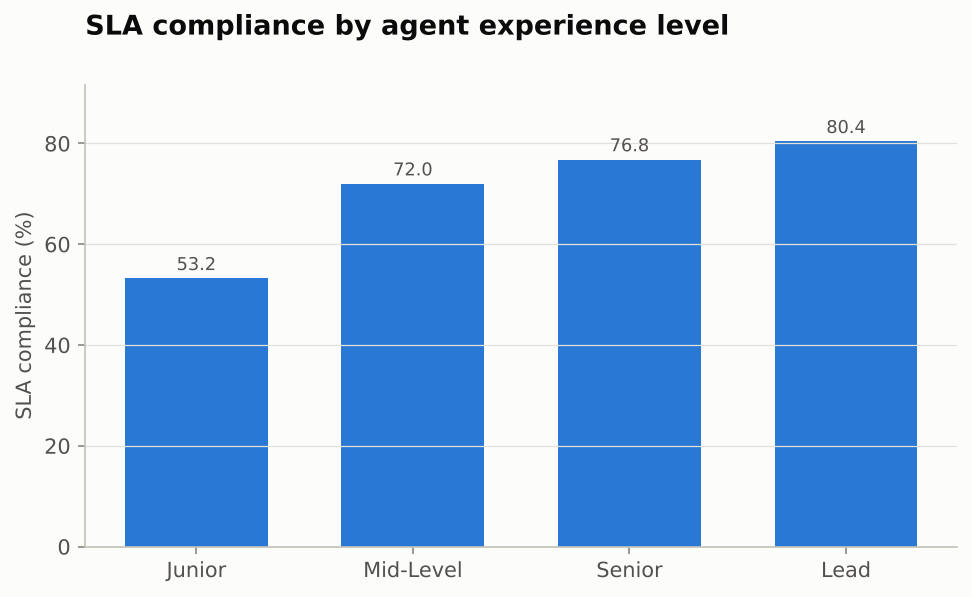

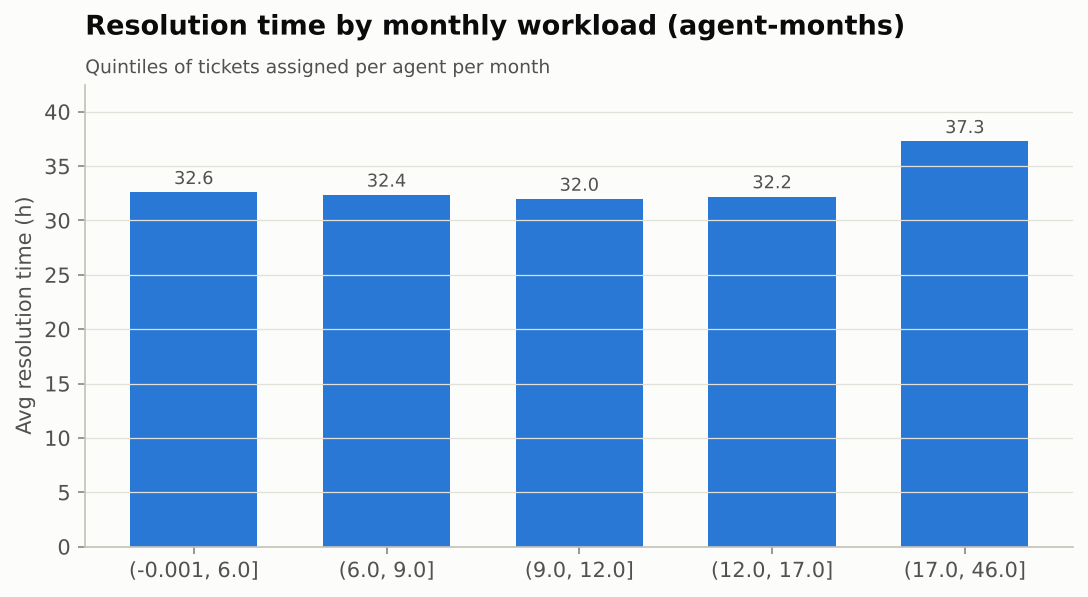

In [4]:
show("33_agent_tickets_resolved", "19_resolution_by_agent", "34_agent_sla_vs_csat", "35_agent_workload", "36_experience_level_sla", "37_workload_vs_resolution")

## Observations (seed 42)
* Experience is the clearest agent-level driver: Junior agents meet SLA on ~53% of tickets vs ~80% for Leads, with ~3x the reopen rate.
* Agent-level SLA compliance and CSAT move together (Spearman ≈ 0.7).
* Workload matters only at the high end: agent-months in the top quintile (≈23 tickets assigned) resolve ~5 h slower and lose ~5 SLA points.
* Billing agents carried the heaviest 2025 load after two departures (see notebook 07).